In [1]:
source('../../../R/preamble.R')

In [2]:
raw = read.tsv('../../../datasets/genomics/02_structural_variation/results/unassigned_junctions.tsv')

In [3]:
j = raw %>% 
    arrange(name, read_pop, gen) %>% 
    filter(seq1 == 'U00096', seq2 == 'U00096') %>% 

    mutate(id = paste(p1, p2, sep = '_')) %>% 

    # Remove variants already in WT
    group_by(id) %>% 
    filter(!'W' %in% read_pop) %>% 
    ungroup() %>% 

    complete(gen = 0:24, nesting(read_pop, pos1, pos2, p1, p2, id), fill = list(freq=0)) %>% 

    group_by(read_pop, id) %>%
    arrange(read_pop, id, gen) %>% 
    filter(
        # Remove variants that don't reach a threshold
        #max(freq) > 90 & sum(freq > 0) >= 2,
        # Remove variants that are not fixed at 60k
        freq[gen==24] > 90,
        # Keep variants that fixed in the last n timepoints
        #all(freq[gen>=23] > 90)
        # Keep variants that are detected twice in a row
        any(freq > 0 & lag(freq) > 0)
    ) %>% 
    ungroup() %>% 

    # Get topology
    mutate(
        topology = case_when(
            substr(pos1, 1, 1) == '=' & substr(pos2, 1, 1) != '=' ~ 'Deletion',
            substr(pos1, 1, 1) != '=' & substr(pos2, 1, 1) == '=' ~ 'Duplication',
            T ~ 'Inversion'
            )
        )

# Deletions

In [4]:
find_overlapping_genes <- function(p1, p2, gene_map) {
  start_pos <- min(p1, p2)
  end_pos <- max(p1, p2)
  
  # Genes overlapping or included in p1-p2
  # (any gene where gene.start <= end_pos AND gene.end >= start_pos)
  overlapping <- gene_map$gene_name[gene_map$start <= end_pos & gene_map$end >= start_pos]
  
  # Previous gene upstream (ends before p1, take the closest one)
  upstream_genes <- gene_map[gene_map$end < start_pos, ]
  prev_upstream <- if (nrow(upstream_genes) > 0) {
    upstream_genes$gene_name[which.max(upstream_genes$end)]
  } else {
    ""
  }
  
  # Next gene downstream (starts after p2, take the closest one)
  downstream_genes <- gene_map[gene_map$start > end_pos, ]
  next_downstream <- if (nrow(downstream_genes) > 0) {
    downstream_genes$gene_name[which.min(downstream_genes$start)]
  } else {
    ""
  }
  
  paste(
    prev_upstream,
    ' [',
    paste(overlapping, collapse = ","),
    '] ',
    next_downstream,
    sep = ""
  )
}

In [5]:
gene_map = read.tsv('../../../datasets/genomics/reference_genome/gene_map.tsv') 

deletions = j %>% filter(topology == 'Deletion') %>% 
    group_by(p1, p2) %>% 
    mutate(
        genes = find_overlapping_genes(p1, p2, gene_map)
    ) %>% 
    mutate(size = p2-p1, label = paste0(genes, ' (', p2-p1, 'bp)')) %>% 
    ungroup()

# CP4-6 prophage deletions
Identified from the VCF files (see raw_no_bg), using missing coverage evidence.

In [6]:
from_vcf = 
    read.tsv('../../../datasets/genomics/01_variant_calling/results/raw_no_bg.tsv') %>% 
    filter(delta < -10000, chrom=='U00096') %>% 
    mutate(
        percent = freq*100, 
        size = -delta, 
        evidence = 'Missing coverage',
        #genes = find_overlapping_genes(pos, pos+size, gene_map),
        genes = 'IS1B [CP4-6 cryptic prophage] yagJ'  
    ) %>% 
    select(read_pop, gen, genes, size, percent, evidence) %>% 
    complete(gen=0:24, nesting(read_pop, genes, size, evidence), fill=list(percent=0)) %>% 
    arrange(read_pop, gen)

# Missing coverage evidence

Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


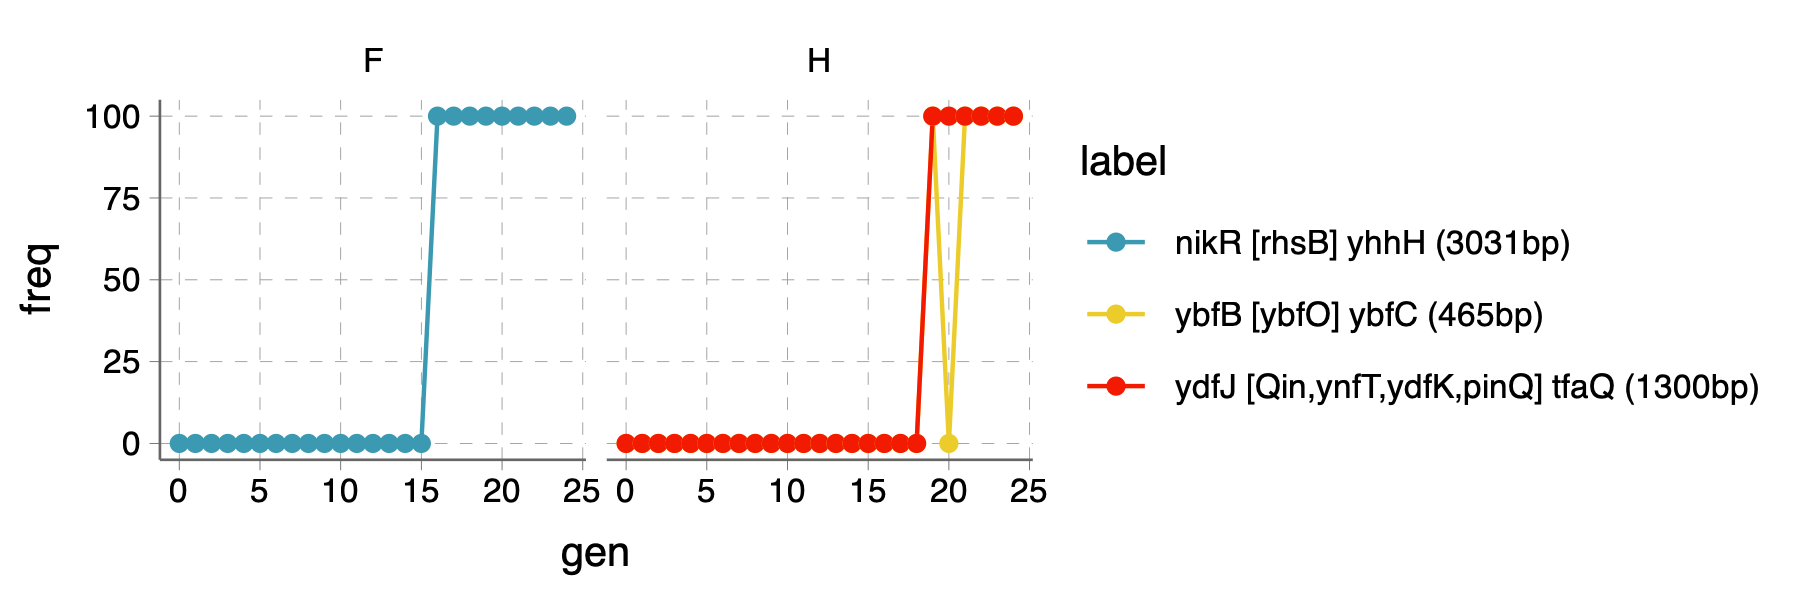

In [7]:
size(2, 6)

mc = read.tsv('../../../datasets/genomics/02_structural_variation/results/unassigned_missing_coverage.tsv') %>% 

    mutate(
        p1 = as.numeric(str_split_i(start, '-', 1)),
        p2 = as.numeric(str_split_i(end, '-', 1))
        ) %>% 

    # Artifact of repetitive tRNA regions
    filter(abs(p1 - 3423722) > 100) %>% 

    filter(seq=='U00096') %>% 
    group_by(p1, p2) %>% 
    mutate(
        genes = find_overlapping_genes(p1, p2, gene_map)
    ) %>% 

    group_by(read_pop, genes) %>% 
    mutate(size=mean(p2-p1), label = paste0(genes, ' (', round(mean(p2-p1)), 'bp)')) %>% 

    # Only keep the ones that are still present at 60k
    group_by(genes) %>%
    filter(
        24 %in% gen
    ) %>% 
    ungroup() %>% 
    mutate(freq = 100) %>% 
    complete(gen = 0:24, nesting(read_pop, genes, label, size), fill=list(freq=0))

mc %>% 

ggplot() + aes(gen, freq, col = label) + facet_wrap(~read_pop) +
    geom_line() +
    geom_point()

In [8]:
all_deletions = bind_rows(
    mc %>% select(read_pop, gen, genes, size, percent=freq) %>% mutate(evidence='Missing coverage'),
    deletions %>% select(read_pop, gen, genes, size, percent=freq) %>% mutate(evidence='New junction'),
    from_vcf
) %>% arrange(read_pop, genes, gen)

all_deletions %>% write.tsv('../../../datasets/genomics/02_structural_variation/results/all_deletions.tsv')

In [9]:
unique_deletions = all_deletions %>% 
    group_by(lineage=read_pop, disrupted_genes = genes, bp=as.integer(size), evidence) %>% 
    summarise(detected = min(gen[percent>0])*2500) %>%
    filter(bp!=777) %>% 
    arrange(lineage, detected)

unique_deletions

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by lineage, disrupted_genes, bp, and
  evidence.
ℹ Output is grouped by lineage, disrupted_genes, and bp.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(lineage, disrupted_genes, bp, evidence))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.


lineage,disrupted_genes,bp,evidence,detected
<chr>,<chr>,<int>,<chr>,<dbl>
A,"yajD [tsx,yajI] nrdR",472,New junction,47500
A,phnF [phnE] phnD,84,New junction,50000
B,lysV [] xapR,157,New junction,37500
B,IS1B [CP4-6 cryptic prophage] yagJ,11471,Missing coverage,50000
E,"yghJ [glcA,glcB,glcG,glcF,glcE,glcD,glcC,yghO,IS5LO] insH9",9771,New junction,55000
E,IS1B [CP4-6 cryptic prophage] yagJ,11471,Missing coverage,60000
F,ycdU [] serX,178,New junction,35000
F,nikR [rhsB] yhhH,3030,Missing coverage,40000
H,ybfB [ybfO] ybfC,465,Missing coverage,47500


# Plot deletions

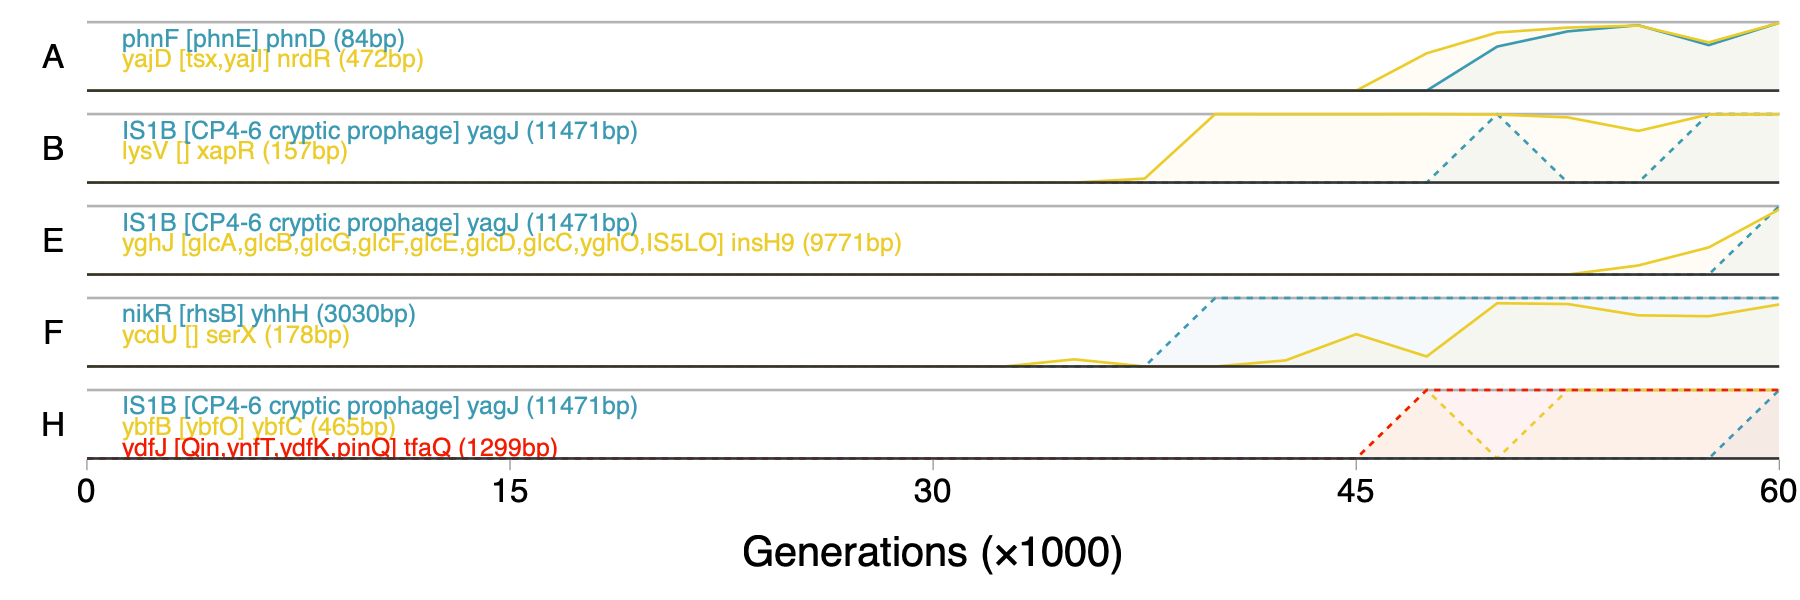

In [10]:
lwd = 0.3

labels = unique_deletions %>%
    group_by(lineage) %>% 
    mutate(
        gen=0.5, 
        rk=dense_rank(disrupted_genes)-1,
        percent=90 - rk*30,
    )

all_deletions %>% filter(size!=777) %>% 
    rename(
        lineage=read_pop,
        disrupted_genes=genes
    ) %>% 
    group_by(lineage) %>% 
    mutate(bp=NA, rk=dense_rank(disrupted_genes)-1) %>% 

ggplot() + aes(
    gen*2.5,
    percent, ymin=0, ymax=percent,
    col = rk, fill = rk, group = disrupted_genes,
    label = paste0(disrupted_genes, ' (', as.integer(bp), 'bp)'),
    lty = fct_rev(evidence)
    ) +

theme(
    panel.grid = eb,
    strip.text.y.left = element_text(angle=0, face='plain'),
    axis.text.y = eb, axis.ticks.y = eb, axis.title.y = eb, axis.line = eb,
) +
facet_wrap(~lineage, ncol=1, strip.position="left") +

#xcont(-1.25, 61.25) +
xcont(0, 60, breaks=seq(0, 60, 15)) +
ycont(0, 100, breaks=seq(0, 100, 50), expand=expansion(add=2)) +

geom_text(
    data = labels,
    size = 2.1, hjust = 0, vjust = 1,
) + nl +

geom_hline(yintercept = 100, lwd = lwd, col = 'grey70') +
geom_ribbon(alpha = 0.05, col = NA) +
geom_line(lwd = lwd) +
geom_hline(yintercept = 0, lwd = lwd, col = 'grey20') +
labs(x = 'Generations (×1000)')

psave('Plots/deletions')

# Plot the flhD IS5

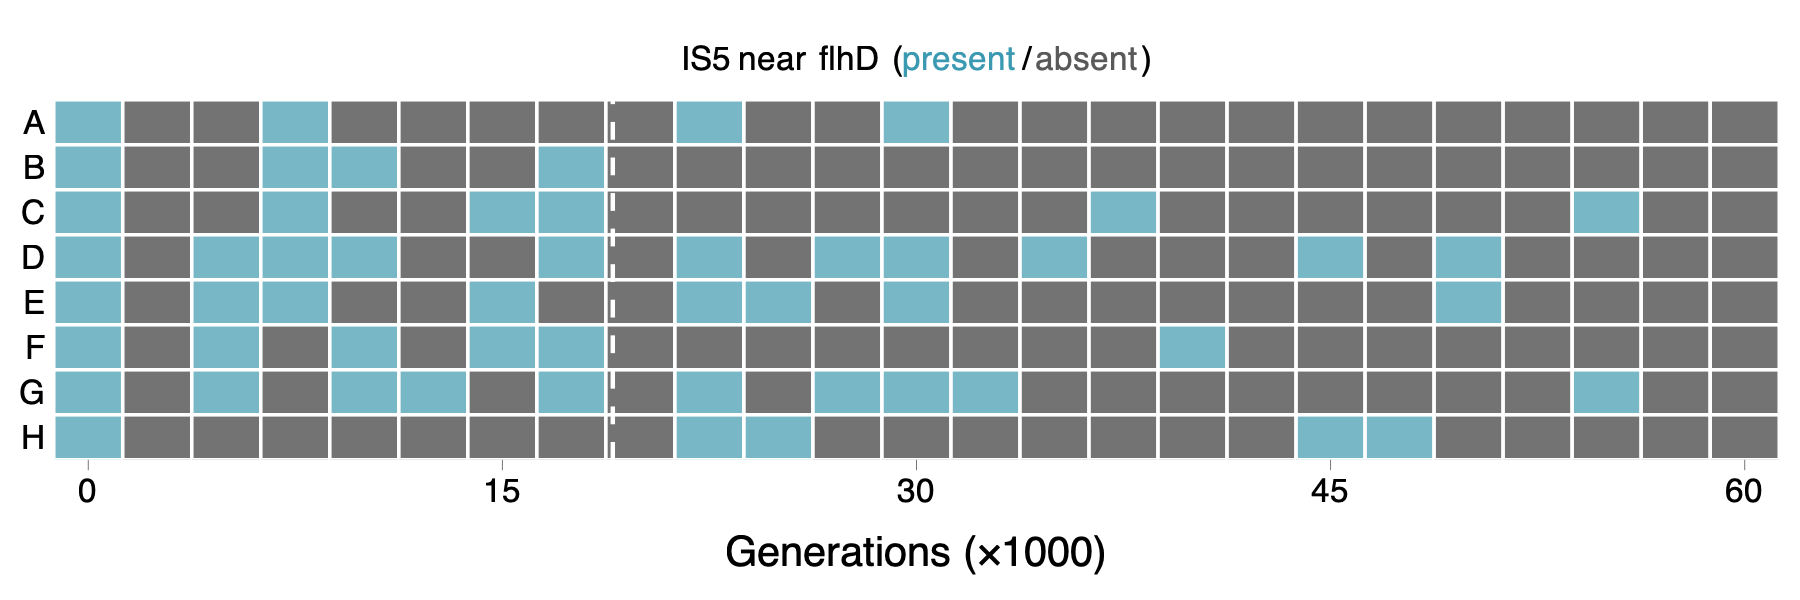

In [11]:
library(ggtext)

deletions %>%
    filter(size==777) %>% 

ggplot() + aes(gen*2.5, fct_rev(read_pop), fill=freq>0) +

    xcont(-1.25, 61.25, breaks=seq(0, 60, 15)) + nl +
    scale_y_discrete(expand=expansion(add=0)) +
    scale_fill_manual(values = c(pal[2], 'grey45')) +
    
    theme(
        panel.grid = eb,
        strip.text.y.right = element_text(angle=0, face='bold'),
        #axis.text.y = eb, 
        axis.ticks.y = eb, axis.title.y = eb, axis.line = eb,
        #axis.title.x = eb
        strip.text = element_markdown()
    ) +

    # Title (using facet for the montage)
    #facet_grid(~'IS5 upstream of flhD') +
    facet_wrap(~ 'title', labeller = as_labeller(c(
        "title" = "IS5 near flhD (<span style='color:#3B9AB2;'>present</span>/<span style='color:grey35;'>absent</span>)"
      ))) +

    geom_tile(col=w, lwd = 0.4) + 
    geom_vline(lwd = 0.5, lty = 2, xintercept = 19, col = w) +
    labs(x = 'Generations (×1000)')

psave('Plots/IS5_flhD')